Statevector:


<IPython.core.display.Latex object>

Circuit:


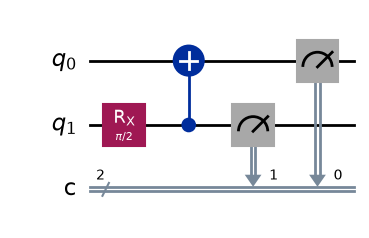

Probability Distribution:


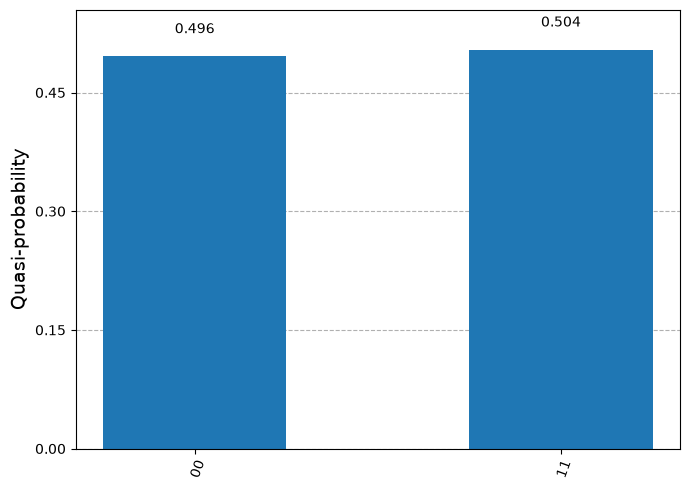

In [27]:
import numpy as np
from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import Statevector
from qiskit.visualization import plot_distribution
from qiskit_aer import AerSimulator

simulator = AerSimulator()

qc = QuantumCircuit(2,2)
qc.rx(np.pi/2, 1)
qc.cx(1,0)
print("Statevector:")
display(Statevector(qc).draw('latex'))

qc.measure([1,0],[1,0])

print("Circuit:")
display(qc.draw('mpl'))

qc_t = transpile(qc, simulator)
counts = simulator.run(qc, shots=2**10).result().get_counts()

print("Probability Distribution:")
plot_distribution(counts)

In [45]:
# define X gate as a function
def x(a_in):
    a_out = a_in ^ 1
    return a_out

In [46]:
# define XOR gate
def cx(a_in, b_in):
    a_out = a_in
    if a_in == 1:
        b_out = X(b_in)
    else:
        b_out = b_in
    return (a_out, b_out)

In [47]:
# Print table for CX gate
print("CX gate:")
print("a | b || a' | b' |")
for a, b in [(0, 0), (0, 1), (1, 0), (1, 1)]:
    ap, bp = cx(a, b)
    print(f"{a} | {b} || {ap}  | {bp}  |")

CX gate:
a | b || a' | b' |
0 | 0 || 0  | 0  |
0 | 1 || 0  | 1  |
1 | 0 || 1  | 1  |
1 | 1 || 1  | 0  |


In [48]:
print("CX gate:")
print("a | b || a'' | b'' |")
for a, b in [(0, 0), (0, 1), (1, 0), (1, 1)]:
    ai, bi = cx(a, b)
    ap, bp = cx(ai, bi)
    print(f"{a} | {b} || {ap}   | {bp}   |")

CX gate:
a | b || a'' | b'' |
0 | 0 || 0   | 0   |
0 | 1 || 0   | 1   |
1 | 0 || 1   | 0   |
1 | 1 || 1   | 1   |


In [49]:
#Reversible AND gate
def ccx(a_in, b_in, c_in):
    a_out = a_in
    b_out = b_in
    if a_in == 1 and b_in == 1:
        c_out = X(c_in)
    else:
        c_out = c_in

    return (a_out, b_out, c_out)

In [51]:
print("CCX gate (with c = 0):")
print("a | b | c || a' | b' | c' |")
for a, b in [(0, 0), (0, 1), (1, 0), (1, 1)]:
    ap, bp, cp = ccx(a, b, 0)
    print(f"{a} | {b} | {c} || {ap}  | {bp}  | {cp}  |")


CCX gate (with c = 0):
a | b | c || a' | b' | c' |
0 | 0 | 0 || 0  | 0  | 0  |
0 | 1 | 0 || 0  | 1  | 0  |
1 | 0 | 0 || 1  | 0  | 0  |
1 | 1 | 0 || 1  | 1  | 1  |


In [54]:
print("CCX gate (with c = 0):")
print("a | b | c || a'' | b'' | c'' |")
for a, b in [(0, 0), (0, 1), (1, 0), (1, 1)]:
    ai, bi, ci = ccx(a, b, 0)
    ap, bp, cp = ccx(a, b, ci)
    print(f"{a} | {b} | {c} || {ap}   | {bp}   | {cp}   |")


CCX gate (with c = 0):
a | b | c || a'' | b'' | c'' |
0 | 0 | 0 || 0   | 0   | 0   |
0 | 1 | 0 || 0   | 1   | 0   |
1 | 0 | 0 || 1   | 0   | 0   |
1 | 1 | 0 || 1   | 1   | 0   |


In [ ]:
# Reversible OR gate
